# 이야기담 — 손그림 15-joint RTMPose 파인튜닝 (전체 데이터) /1차 (비율은 7:1:2)
**런타임: A100 GPU.** 위에서부터 순서대로 실행.

반영 사항: BN / head까지 pretrained init / 이미지 단위 train·val·test split / 이미지 리사이즈(JPEG, 로딩 병목 해결) / tensorboard / Drive 저장 + `--resume`

세션 끊기면: Cell 1~8 재실행(Cell 4는 seed 고정이라 split 동일) → Cell 10 실행 시 이어서 학습.

## 1. Drive 마운트 + GPU 확인

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/yiyagidam'
os.makedirs(f'{DRIVE}/work_dirs', exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv
print('CPU:', os.cpu_count())

In [ ]:
!ls -la /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_full_712/
!tail -20 /content/drive/MyDrive/yiyagidam/train_full_712.log

## 2. conda 환경 + mmpose 설치
마지막 줄에 `CUDA True`가 찍혀야 함.

In [ ]:
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future tensorboard
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"
!{E} python -c "import torch, mmpose, mmcv, mmdet, tensorboard; print('CUDA', torch.cuda.is_available(), '| mmpose', mmpose.__version__, '| mmcv', mmcv.__version__)"

## 3. 데이터 다운로드 + 압축 해제 (15~20분)

In [ ]:
%cd /content
!wget -q -nc https://dl.fbaipublicfiles.com/amateur_drawings/amateur_drawings_annotations.json
!test -d /content/data/amateur_drawings || wget -q -nc https://dl.fbaipublicfiles.com/amateur_drawings/amateur_drawings.tar
!mkdir -p /content/data && test -f amateur_drawings.tar && tar -xf amateur_drawings.tar -C /content/data/ --skip-old-files && rm -f amateur_drawings.tar
!wget -q -nc https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/rtmpose-m_simcc-coco_pt-aic-coco_420e-256x192-d8dd5ca4_20230127.pth -O rtmpose-m_coco-256x192.pth
!find /content/data -type f | wc -l

## 4. 17→15 joint 변환 + 이미지 단위 train/val/test split

In [ ]:
import json, random
import numpy as np

COCO_IDX = {n: i for i, n in enumerate([
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle"])}
J15 = ["nose", "neck", "right_shoulder", "right_elbow", "right_wrist",
       "left_shoulder", "left_elbow", "left_wrist", "pelvis",
       "right_hip", "right_knee", "right_ankle", "left_hip", "left_knee", "left_ankle"]
SKEL_1BASED = [[a + 1, b + 1] for a, b in [(0,1),(1,2),(2,3),(3,4),(1,5),(5,6),(6,7),
                                           (1,8),(8,9),(9,10),(10,11),(8,12),(12,13),(13,14)]]

def to15(k17):
    k = np.array(k17, dtype=np.float32).reshape(17, 3)
    g = lambda n: k[COCO_IDX[n]]
    mid = lambda a, b: np.array([(g(a)[0]+g(b)[0])/2, (g(a)[1]+g(b)[1])/2, min(g(a)[2], g(b)[2])])
    return np.stack([g("nose"), mid("left_shoulder", "right_shoulder"),
                     g("right_shoulder"), g("right_elbow"), g("right_wrist"),
                     g("left_shoulder"), g("left_elbow"), g("left_wrist"),
                     mid("left_hip", "right_hip"),
                     g("right_hip"), g("right_knee"), g("right_ankle"),
                     g("left_hip"), g("left_knee"), g("left_ankle")])

raw = json.load(open('/content/amateur_drawings_annotations.json'))
anns = []
for a in raw['annotations']:
    if a.get('num_keypoints', 0) == 0:
        continue
    k = to15(a['keypoints'])
    if (k[:, 2] > 0).sum() < 8:
        continue
    anns.append(dict(id=a['id'], image_id=a['image_id'], bbox=a['bbox'], kpts=k.tolist()))
img_by_id = {im['id']: im for im in raw['images']}
print('annotations:', len(anns))

# 이미지 단위 split (train 70% / val 10% / test 20%  =  7:1:2)
random.seed(42)
ids = sorted({a['image_id'] for a in anns})
random.shuffle(ids)
n = len(ids)
n_train = int(n * 0.7)
n_val = int(n * 0.1)
SPLIT = {'train': set(ids[:n_train]),
         'val': set(ids[n_train:n_train + n_val]),
         'test': set(ids[n_train + n_val:])}   # 나머지 전부 test (~20%)
SPLIT['smoke_train'] = set(random.sample(sorted(SPLIT['train']), 3000))
SPLIT['smoke_val'] = set(random.sample(sorted(SPLIT['val']), 500))
assert not (SPLIT['train'] & SPLIT['val']) and not (SPLIT['train'] & SPLIT['test']) and not (SPLIT['val'] & SPLIT['test'])
json.dump({k: sorted(v) for k, v in SPLIT.items()}, open(f'{DRIVE}/split_ids_712.json', 'w'))
print({k: len(v) for k, v in SPLIT.items()})

## 5. 이미지 리사이즈(긴 변 ≤1024, JPEG) + COCO json 생성 (좌표 스케일 포함)

In [ ]:
import os
from PIL import Image
from concurrent.futures import ProcessPoolExecutor

SRC, DST, MAX = '/content/data/', '/content/data_small/', 1024
used = sorted(set().union(*[SPLIT[s] for s in ['train', 'val', 'test']]))

def proc(iid):
    fn0 = img_by_id[iid]['file_name']
    fn = os.path.splitext(fn0)[0] + '.jpg'
    img = Image.open(SRC + fn0)
    w, h = img.size
    s = min(1.0, MAX / max(w, h))
    if not os.path.exists(DST + fn):
        os.makedirs(os.path.dirname(DST + fn), exist_ok=True)
        img = img.convert('RGB')
        if s < 1.0:
            img = img.resize((round(w * s), round(h * s)), Image.BILINEAR)
        img.save(DST + fn, quality=95)
    return iid, (fn, s, round(w * s), round(h * s))

with ProcessPoolExecutor(os.cpu_count()) as ex:
    INFO = dict(ex.map(proc, used, chunksize=256))
print('resized:', len(INFO))

def write_coco(split, dst):
    ids = SPLIT[split]
    out_anns = []
    for a in anns:
        if a['image_id'] not in ids:
            continue
        s = INFO[a['image_id']][1]
        flat, nv = [], 0
        for x, y, v in a['kpts']:
            flat += [x * s, y * s, int(v)]
            nv += int(v > 0)
        bx = [v * s for v in a['bbox']]
        out_anns.append(dict(id=a['id'], image_id=a['image_id'], category_id=1, bbox=bx,
                             area=bx[2] * bx[3], iscrowd=0, keypoints=flat, num_keypoints=nv))
    imgs = [dict(id=i, file_name=INFO[i][0], width=INFO[i][2], height=INFO[i][3]) for i in ids]
    json.dump(dict(images=imgs, annotations=out_anns,
                   categories=[dict(id=1, name='human', supercategory='drawing',
                                    keypoints=J15, skeleton=SKEL_1BASED)]), open(dst, 'w'))
    print(f'{dst}: images {len(imgs)} / anns {len(out_anns)}')

for sp in SPLIT:
    write_coco(sp, f'/content/{sp}_coco.json')

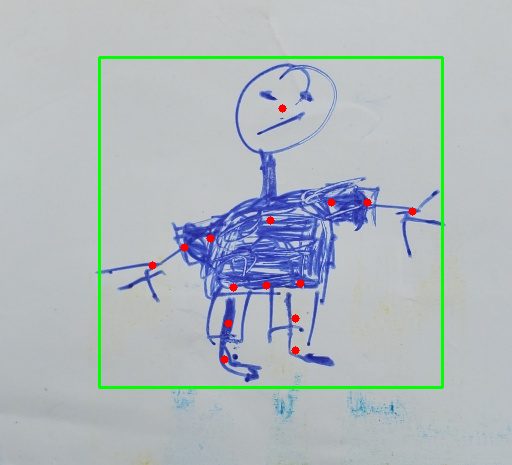

In [ ]:
# 확인용: keypoint/bbox가 그림과 맞는지
import cv2
from google.colab.patches import cv2_imshow
d = json.load(open('/content/val_coco.json'))
a = random.choice(d['annotations'])
im = next(i for i in d['images'] if i['id'] == a['image_id'])
v = cv2.imread(DST + im['file_name'])
k = a['keypoints']
for i in range(0, 45, 3):
    if k[i + 2] > 0:
        cv2.circle(v, (int(k[i]), int(k[i + 1])), 4, (0, 0, 255), -1)
x, y, w, h = map(int, a['bbox'])
cv2.rectangle(v, (x, y), (x + w, y + h), (0, 255, 0), 2)
cv2_imshow(v)

## 6. dataset_info (15-joint, sigma 포함)

In [ ]:
%%writefile /content/mmpose/configs/_base_/datasets/drawing15.py
dataset_info = dict(
    dataset_name='drawing15',
    paper_info=dict(),
    keypoint_info={
        0: dict(name='nose', id=0, color=[255, 128, 0], type='upper', swap='', sigma=0.026),
        1: dict(name='neck', id=1, color=[255, 128, 0], type='upper', swap='', sigma=0.079),
        2: dict(name='right_shoulder', id=2, color=[255, 128, 0], type='upper', swap='left_shoulder', sigma=0.079),
        3: dict(name='right_elbow', id=3, color=[255, 128, 0], type='upper', swap='left_elbow', sigma=0.072),
        4: dict(name='right_wrist', id=4, color=[255, 128, 0], type='upper', swap='left_wrist', sigma=0.062),
        5: dict(name='left_shoulder', id=5, color=[0, 255, 0], type='upper', swap='right_shoulder', sigma=0.079),
        6: dict(name='left_elbow', id=6, color=[0, 255, 0], type='upper', swap='right_elbow', sigma=0.072),
        7: dict(name='left_wrist', id=7, color=[0, 255, 0], type='upper', swap='right_wrist', sigma=0.062),
        8: dict(name='pelvis', id=8, color=[255, 128, 0], type='lower', swap='', sigma=0.107),
        9: dict(name='right_hip', id=9, color=[255, 128, 0], type='lower', swap='left_hip', sigma=0.107),
        10: dict(name='right_knee', id=10, color=[255, 128, 0], type='lower', swap='left_knee', sigma=0.087),
        11: dict(name='right_ankle', id=11, color=[255, 128, 0], type='lower', swap='left_ankle', sigma=0.089),
        12: dict(name='left_hip', id=12, color=[0, 255, 0], type='lower', swap='right_hip', sigma=0.107),
        13: dict(name='left_knee', id=13, color=[0, 255, 0], type='lower', swap='right_knee', sigma=0.087),
        14: dict(name='left_ankle', id=14, color=[0, 255, 0], type='lower', swap='right_ankle', sigma=0.089),
    },
    skeleton_info={
        0: dict(link=('nose', 'neck'), id=0, color=[0, 255, 255]),
        1: dict(link=('neck', 'right_shoulder'), id=1, color=[255, 128, 0]),
        2: dict(link=('right_shoulder', 'right_elbow'), id=2, color=[255, 128, 0]),
        3: dict(link=('right_elbow', 'right_wrist'), id=3, color=[255, 128, 0]),
        4: dict(link=('neck', 'left_shoulder'), id=4, color=[0, 255, 0]),
        5: dict(link=('left_shoulder', 'left_elbow'), id=5, color=[0, 255, 0]),
        6: dict(link=('left_elbow', 'left_wrist'), id=6, color=[0, 255, 0]),
        7: dict(link=('neck', 'pelvis'), id=7, color=[0, 255, 255]),
        8: dict(link=('pelvis', 'right_hip'), id=8, color=[255, 128, 0]),
        9: dict(link=('right_hip', 'right_knee'), id=9, color=[255, 128, 0]),
        10: dict(link=('right_knee', 'right_ankle'), id=10, color=[255, 128, 0]),
        11: dict(link=('pelvis', 'left_hip'), id=11, color=[0, 255, 0]),
        12: dict(link=('left_hip', 'left_knee'), id=12, color=[0, 255, 0]),
        13: dict(link=('left_knee', 'left_ankle'), id=13, color=[0, 255, 0]),
    },
    joint_weights=[1.] * 15,
    sigmas=[0.026, 0.079, 0.079, 0.072, 0.062, 0.079, 0.072, 0.062,
            0.107, 0.107, 0.087, 0.089, 0.107, 0.087, 0.089])

## 7. head까지 쓰는 init checkpoint (17→15 final layer만 제거)

In [ ]:
%%writefile /content/strip_ckpt.py
import torch
sd = torch.load('/content/rtmpose-m_coco-256x192.pth', map_location='cpu')['state_dict']
for k in [k for k in sd if k.startswith('head.final_layer')]:
    sd.pop(k)
torch.save({'state_dict': sd}, '/content/rtmpose-m_init15.pth')
print('ok')

In [ ]:
!/usr/local/miniconda/bin/conda run -n mmpose_env python /content/strip_ckpt.py

## 8. config 생성 (smoke / full)
A100 80GB 기준 batch 256 / lr 1e-3 / warmup 500 iter.

In [ ]:
import os
DRIVE = '/content/drive/MyDrive/yiyagidam'
TEMPLATE = r'''
_base_ = ['../../../_base_/default_runtime.py']

max_epochs = __EPOCHS__
stage2_num_epochs = __STAGE2__
base_lr = __LR__
train_cfg = dict(max_epochs=max_epochs, val_interval=1)
randomness = dict(seed=21)

optim_wrapper = dict(type='OptimWrapper',
    optimizer=dict(type='AdamW', lr=base_lr, weight_decay=0.05),
    paramwise_cfg=dict(norm_decay_mult=0, bias_decay_mult=0, bypass_duplicate=True))
param_scheduler = [
    dict(type='LinearLR', start_factor=1.0e-5, by_epoch=False, begin=0, end=__WARMUP__),
    dict(type='CosineAnnealingLR', eta_min=base_lr * 0.05, begin=max_epochs // 2, end=max_epochs,
         T_max=max_epochs // 2, by_epoch=True, convert_to_iter_based=True),
]

codec = dict(type='SimCCLabel', input_size=(192, 256), sigma=(4.9, 5.66),
             simcc_split_ratio=2.0, normalize=False, use_dark=False)

model = dict(
    type='TopdownPoseEstimator',
    data_preprocessor=dict(type='PoseDataPreprocessor', mean=[123.675, 116.28, 103.53],
                           std=[58.395, 57.12, 57.375], bgr_to_rgb=True),
    backbone=dict(_scope_='mmdet', type='CSPNeXt', arch='P5', expand_ratio=0.5,
                  deepen_factor=0.67, widen_factor=0.75, out_indices=(4, ), channel_attention=True,
                  norm_cfg=dict(type='BN'), act_cfg=dict(type='SiLU')),
    head=dict(type='RTMCCHead', in_channels=768, out_channels=15,
              input_size=codec['input_size'],
              in_featuremap_size=tuple([s // 32 for s in codec['input_size']]),
              simcc_split_ratio=codec['simcc_split_ratio'], final_layer_kernel_size=7,
              gau_cfg=dict(hidden_dims=256, s=128, expansion_factor=2, dropout_rate=0., drop_path=0.,
                           act_fn='SiLU', use_rel_bias=False, pos_enc=False),
              loss=dict(type='KLDiscretLoss', use_target_weight=True, beta=10., label_softmax=True),
              decoder=codec),
    test_cfg=dict(flip_test=True))
load_from = '/content/rtmpose-m_init15.pth'

backend_args = dict(backend='local')
def albu(p):
    return dict(type='Albumentation', transforms=[
        dict(type='Blur', p=0.1), dict(type='MedianBlur', p=0.1),
        dict(type='CoarseDropout', max_holes=1, max_height=0.4, max_width=0.4,
             min_holes=1, min_height=0.2, min_width=0.2, p=p)])
train_pipeline = [
    dict(type='LoadImage', backend_args=backend_args), dict(type='GetBBoxCenterScale'),
    dict(type='RandomFlip', direction='horizontal'), dict(type='RandomHalfBody'),
    dict(type='RandomBBoxTransform', scale_factor=[0.6, 1.4], rotate_factor=80),
    dict(type='TopdownAffine', input_size=codec['input_size']),
    dict(type='mmdet.YOLOXHSVRandomAug'), albu(1.0),
    dict(type='GenerateTarget', encoder=codec), dict(type='PackPoseInputs')]
train_pipeline_stage2 = [
    dict(type='LoadImage', backend_args=backend_args), dict(type='GetBBoxCenterScale'),
    dict(type='RandomFlip', direction='horizontal'), dict(type='RandomHalfBody'),
    dict(type='RandomBBoxTransform', shift_factor=0., scale_factor=[0.75, 1.25], rotate_factor=60),
    dict(type='TopdownAffine', input_size=codec['input_size']),
    dict(type='mmdet.YOLOXHSVRandomAug'), albu(0.5),
    dict(type='GenerateTarget', encoder=codec), dict(type='PackPoseInputs')]
val_pipeline = [
    dict(type='LoadImage', backend_args=backend_args), dict(type='GetBBoxCenterScale'),
    dict(type='TopdownAffine', input_size=codec['input_size']), dict(type='PackPoseInputs')]

dataset_type, data_mode, data_root = 'CocoDataset', 'topdown', '/content/'
META = dict(from_file='/content/mmpose/configs/_base_/datasets/drawing15.py')

def _ds(ann, pipe, test=False):
    return dict(type=dataset_type, data_root=data_root, data_mode=data_mode, ann_file=ann,
                data_prefix=dict(img='data_small/'), metainfo=META, test_mode=test, pipeline=pipe)

train_dataloader = dict(batch_size=__BATCH__, num_workers=__WORKERS__, persistent_workers=True,
    sampler=dict(type='DefaultSampler', shuffle=True), dataset=_ds('__TRAIN__', train_pipeline))
val_dataloader = dict(batch_size=__BATCH__, num_workers=__WORKERS__, persistent_workers=True, drop_last=False,
    sampler=dict(type='DefaultSampler', shuffle=False, round_up=False),
    dataset=_ds('__VAL__', val_pipeline, True))
test_dataloader = dict(batch_size=__BATCH__, num_workers=__WORKERS__, persistent_workers=True, drop_last=False,
    sampler=dict(type='DefaultSampler', shuffle=False, round_up=False),
    dataset=_ds('__TEST__', val_pipeline, True))
val_evaluator = dict(type='CocoMetric', ann_file=data_root + '__VAL__')
test_evaluator = dict(type='CocoMetric', ann_file=data_root + '__TEST__')

default_hooks = dict(checkpoint=dict(save_best='coco/AP', rule='greater', max_keep_ckpts=3, interval=1))
custom_hooks = [
    dict(type='EMAHook', ema_type='ExpMomentumEMA', momentum=0.0002, update_buffers=True, priority=49),
    dict(type='mmdet.PipelineSwitchHook', switch_epoch=max_epochs - stage2_num_epochs,
         switch_pipeline=train_pipeline_stage2)]
visualizer = dict(type='PoseLocalVisualizer', name='visualizer',
                  vis_backends=[dict(type='LocalVisBackend'), dict(type='TensorboardVisBackend')])
work_dir = '__WORKDIR__'
'''

CFG_DIR = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/'

def make_cfg(name, epochs, stage2, batch, lr, warmup, train, val, test):
    s = TEMPLATE
    for k, v in dict(EPOCHS=epochs, STAGE2=stage2, LR=lr, WARMUP=warmup, BATCH=batch,
                     WORKERS=min(os.cpu_count(), 16), TRAIN=train, VAL=val, TEST=test,
                     WORKDIR=f'{DRIVE}/work_dirs/{name}').items():
        s = s.replace(f'__{k}__', str(v))
    p = CFG_DIR + name + '.py'
    open(p, 'w').write(s)
    print('saved', p)
    return p

SMOKE_CFG = make_cfg('drawing15_smoke_712', 2, 1, 256, 1e-3, 20,
                     'smoke_train_coco.json', 'smoke_val_coco.json', 'smoke_val_coco.json')
FULL_CFG = make_cfg('drawing15_full_712', 30, 5, 256, 1e-3, 500,
                    'train_coco.json', 'val_coco.json', 'test_coco.json')

## 9. 스모크 테스트 (2 epoch)
통과 기준: `CUDA available: True` / missing keys = `head.final_layer`만 / loss 감소 / 에러 없음. AP는 0 근처여도 정상.

In [ ]:
!MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/mmpose/tools/train.py {SMOKE_CFG} 2>&1 | grep -E "CUDA available|missing keys|Epoch\(|Error|error"

## 10. 전체 학습 (백그라운드, `--resume`으로 이어서 학습)

In [ ]:
!nohup env MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/mmpose/tools/train.py {FULL_CFG} --resume > {DRIVE}/train_full_712.log 2>&1 &

In [ ]:
# 모니터링 (반복 실행) — GPU 85%↑ 목표
!nvidia-smi --query-gpu=utilization.gpu,memory.used --format=csv,noheader
!grep -E "Epoch\(train\)|coco/AP:" {DRIVE}/train_full_712.log | tail -4

In [ ]:
!ls /content/eval_pck.py
!ls {DRIVE}/work_dirs/drawing15_full_712/best_coco_AP_*.pth

In [ ]:
!ls -la {DRIVE}/work_dirs/drawing15_full_712/
!cat {DRIVE}/work_dirs/drawing15_full_712/last_checkpoint

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /content/drive/MyDrive/yiyagidam/work_dirs/drawing15_full_712

In [ ]:
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/eval_pck.py
# 파인튜닝 모델 test coco/AP (GT bbox 기준)
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/mmpose/tools/test.py \
  {FULL_CFG} $(ls {DRIVE}/work_dirs/drawing15_full_712/best_coco_AP_*.pth | tail -1)

## 11. test set 평가: zero-shot vs 파인튜닝 + 관절별 PCK
`MEAN13_orig` = neck/pelvis(중점 joint) 제외 13개 평균.

In [ ]:
%%writefile /content/eval_pck.py
import json, glob
import numpy as np
from collections import defaultdict
from mmpose.apis import init_model, inference_topdown

D = '/content/drive/MyDrive/yiyagidam'
C = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/'
FT = (C + 'drawing15_full_712.py', sorted(glob.glob(f'{D}/work_dirs/drawing15_full_712/best_coco_AP_*.pth'))[-1])
ZS = (C + 'rtmpose-m_8xb256-420e_coco-256x192.py', '/content/rtmpose-m_coco-256x192.pth')
NAMES = ["nose", "neck", "r_shoulder", "r_elbow", "r_wrist", "l_shoulder", "l_elbow", "l_wrist",
         "pelvis", "r_hip", "r_knee", "r_ankle", "l_hip", "l_knee", "l_ankle"]
ORIG13 = [i for i in range(15) if i not in (1, 8)]

def c17to15(k):
    m = lambda a, b: (k[a] + k[b]) / 2
    return np.stack([k[0], m(5, 6), k[6], k[8], k[10], k[5], k[7], k[9], m(11, 12),
                     k[12], k[14], k[16], k[11], k[13], k[15]])

coco = json.load(open('/content/test_coco.json'))
files = {im['id']: im['file_name'] for im in coco['images']}
by_img = defaultdict(list)
for a in coco['annotations']:
    by_img[a['image_id']].append(a)

def run(cfg, ckpt, is17):
    model = init_model(cfg, ckpt, device='cuda:0')
    hit = {t: np.zeros(15) for t in (0.05, 0.1)}
    cnt = np.zeros(15)
    for iid, anns in by_img.items():
        boxes = np.array([[b[0], b[1], b[0] + b[2], b[1] + b[3]] for b in (a['bbox'] for a in anns)])
        res = inference_topdown(model, '/content/data_small/' + files[iid], bboxes=boxes, bbox_format='xyxy')
        for a, r in zip(anns, res):
            p = r.pred_instances.keypoints[0]
            p = c17to15(p) if is17 else p
            gt = np.array(a['keypoints'], dtype=np.float32).reshape(15, 3)
            vis = gt[:, 2] > 0
            d = np.linalg.norm(p - gt[:, :2], axis=1) / max(a['bbox'][2], a['bbox'][3])
            for t in hit:
                hit[t] += (d < t) & vis
            cnt += vis
    return {t: hit[t] / np.maximum(cnt, 1) for t in hit}

zs, ft = run(*ZS, True), run(*FT, False)
rows = ['joint,zs@0.05,ft@0.05,zs@0.1,ft@0.1']
for i, n in enumerate(NAMES):
    rows.append(f'{n},{zs[.05][i]:.3f},{ft[.05][i]:.3f},{zs[.1][i]:.3f},{ft[.1][i]:.3f}')
for tag, idx in [('MEAN15', list(range(15))), ('MEAN13_orig', ORIG13)]:
    rows.append(f'{tag},{zs[.05][idx].mean():.3f},{ft[.05][idx].mean():.3f},{zs[.1][idx].mean():.3f},{ft[.1][idx].mean():.3f}')
out = '\n'.join(rows)
print('FT ckpt:', FT[1]); print(out)
open(f'{D}/pck_test.csv', 'w').write(out)

Overwriting /content/eval_pck.py


In [ ]:
!/usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/eval_pck.py
# 파인튜닝 모델 test coco/AP (GT bbox 기준)
!/usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/mmpose/tools/test.py \
  {FULL_CFG} $(ls {DRIVE}/work_dirs/drawing15_full_712/best_coco_AP_*.pth | tail -1)

In [ ]:
!nohup bash -c 'for i in 1 2 3 4 5; do env MPLBACKEND=Agg PYTHONUNBUFFERED=1 /usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env python -u /content/mmpose/tools/train.py {FULL_CFG} --resume && break; sleep 60; done' >> {DRIVE}/train_full_712.log 2>&1 &

##모델

In [ ]:
%%writefile /content/export_ckpt.py
import torch, shutil, os
D = '/content/drive/MyDrive/yiyagidam'
OUT = f'{D}/deploy_712'
os.makedirs(OUT, exist_ok=True)
ck = torch.load(f'{D}/work_dirs/drawing15_full_712/best_coco_AP_epoch_30.pth', map_location='cpu')
torch.save({'state_dict': ck['state_dict'], 'meta': ck.get('meta', {})}, f'{OUT}/rtmpose-m_drawing15_712_ep30.pth')
shutil.copy(f'{D}/work_dirs/drawing15_full_712/drawing15_full_712.py', OUT)
shutil.copy('/content/mmpose/configs/_base_/datasets/drawing15.py', OUT)
shutil.copy('/content/rtmpose-m_coco-256x192.pth', OUT) if False else None
print(os.listdir(OUT))

Writing /content/export_ckpt.py


In [ ]:
!/usr/local/miniconda/bin/conda run -n mmpose_env python /content/export_ckpt.py
!ls -la {DRIVE}/deploy_712

##테스트

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"

# 학습 때 쓴 dataset_info / config를 Drive(deploy)에서 복원
D = '/content/drive/MyDrive/yiyagidam/deploy_712'
!cp {D}/drawing15.py /content/mmpose/configs/_base_/datasets/drawing15.py
!cp {D}/drawing15_full_712.py /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full_712.py

!{E} python -c "import torch, mmpose, mmcv, mmdet; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available(), '| mmpose', mmpose.__version__)"

In [ ]:
!MPLBACKEND=Agg /usr/local/miniconda/bin/conda run -n mmpose_env python -c "import torch, mmpose, mmcv, mmdet; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available(), '| mmpose', mmpose.__version__)"

Traceback (most recent call last):
  File "<string>", line 1, in <module>
AttributeError: module 'mmpose' has no attribute '__version__'
ERROR conda.cli.main_run:execute(148): `conda run python -c import torch, mmpose, mmcv, mmdet; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available(), '| mmpose', mmpose.__version__)` failed. (See above for error)


In [ ]:
%%writefile /content/infer_drawing.py
import os
os.environ['MPLBACKEND'] = 'Agg'   # ← 추가: Colab의 inline backend 값 덮어쓰기
import sys, glob, argparse
import numpy as np, cv2
from mmpose.apis import init_model, inference_topdown

D = '/content/drive/MyDrive/yiyagidam/deploy_712'
CFG  = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full_712.py'   # ← 변경
CKPT = f'{D}/rtmpose-m_drawing15_712_ep30.pth'

NAMES = ["nose","neck","r_shoulder","r_elbow","r_wrist","l_shoulder","l_elbow","l_wrist",
         "pelvis","r_hip","r_knee","r_ankle","l_hip","l_knee","l_ankle"]
SKEL = [(0,1),(1,2),(2,3),(3,4),(1,5),(5,6),(6,7),(1,8),(8,9),(9,10),(10,11),(8,12),(12,13),(13,14)]
# 오른쪽=주황, 왼쪽=초록, 몸통=파랑 (BGR)
def col(a, b):
    if {a, b} & {2,3,4,9,10,11}: return (0, 128, 255)
    if {a, b} & {5,6,7,12,13,14}: return (0, 220, 0)
    return (255, 128, 0)

ap = argparse.ArgumentParser()
ap.add_argument('src', help='이미지 파일 또는 폴더')
ap.add_argument('--out', default='/content/pred_out')
ap.add_argument('--bbox', default=None, help='x1,y1,x2,y2 (생략하면 이미지 전체)')
ap.add_argument('--pad', type=float, default=0.0, help='bbox 여유 비율, 예: 0.05')
ap.add_argument('--thr', type=float, default=0.3, help='keypoint score 표시 기준')
args = ap.parse_args()
os.makedirs(args.out, exist_ok=True)

files = sorted(sum([glob.glob(os.path.join(args.src, e)) for e in ('*.jpg','*.jpeg','*.png','*.JPG','*.PNG','*.webp')], [])) \
        if os.path.isdir(args.src) else [args.src]

model = init_model(CFG, CKPT, device='cuda:0')

for f in files:
    img = cv2.imread(f)
    if img is None:
        print('skip', f); continue
    # 긴 변 1024로 축소 (학습 때와 동일한 스케일 범위)
    h, w = img.shape[:2]
    s = min(1.0, 1024 / max(h, w))
    if s < 1: img = cv2.resize(img, (round(w*s), round(h*s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]

    if args.bbox:
        x1, y1, x2, y2 = [float(v) * (s if s < 1 else 1) for v in args.bbox.split(',')]
    else:
        x1, y1, x2, y2 = 0, 0, w, h
    px, py = (x2-x1)*args.pad, (y2-y1)*args.pad
    box = np.array([[max(0,x1-px), max(0,y1-py), min(w,x2+px), min(h,y2+py)]], dtype=np.float32)


    r = inference_topdown(model, img, bboxes=box, bbox_format='xyxy')[0].pred_instances
    kp, sc = r.keypoints[0], r.keypoint_scores[0]

    vis = img.copy()
    t = max(2, round(max(h, w) / 300))
    for a, b in SKEL:
        if sc[a] > args.thr and sc[b] > args.thr:
            cv2.line(vis, tuple(map(int, kp[a])), tuple(map(int, kp[b])), col(a, b), t)
    for i, (x, y) in enumerate(kp):
        if sc[i] > args.thr:
            cv2.circle(vis, (int(x), int(y)), t*2, (0, 0, 255), -1)
            cv2.circle(vis, (int(x), int(y)), t*2, (255, 255, 255), 1)
    name = os.path.splitext(os.path.basename(f))[0]
    cv2.imwrite(f'{args.out}/{name}_pose.jpg', vis)
    print(f'[{name}] mean score {sc.mean():.2f} | ' +
          ' '.join(f'{n}:{v:.2f}' for n, v in zip(NAMES, sc)))
    np.save(f'{args.out}/{name}_kpts.npy', np.concatenate([kp, sc[:, None]], 1))  # (15,3): x,y,score

In [ ]:
from google.colab import files
import os, glob, shutil
shutil.rmtree('/content/test_imgs', ignore_errors=True); os.makedirs('/content/test_imgs')
up = files.upload()                       # 사진 여러 장 선택 가능
for n in up: shutil.move(n, f'/content/test_imgs/{n}')

!/usr/local/miniconda/bin/conda run --no-capture-output -n mmpose_env \
  python -u /content/infer_drawing.py /content/test_imgs --out /content/pred_out

from google.colab.patches import cv2_imshow
import cv2
for p in sorted(glob.glob('/content/pred_out/*_pose.jpg')):
    print(p); cv2_imshow(cv2.imread(p))